In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt

In [4]:
import seaborn as sns

In [5]:
df = pd.read_csv('/content/StudentsPerformance.csv')

In [6]:
print("Dataset uploaded successfully!")

Dataset uploaded successfully!


In [7]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [8]:
df.tail()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


In [9]:
print("Shape of dataset:", df.shape)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Shape of dataset: (1000, 8)
Number of rows: 1000
Number of columns: 8


In [10]:
print(df.columns)

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [12]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [13]:
print(df.isnull().sum())

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


In [14]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [15]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [16]:
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].mean())

# Fill missing values in categorical columns with their mode
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values handled successfully!")

Missing values handled successfully!


In [17]:
print("Duplicates before cleaning:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Check duplicates after removing
print("Duplicates after cleaning:", df.duplicated().sum())

Duplicates before cleaning: 0
Duplicates after cleaning: 0


In [18]:
print(df.isnull().sum())

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


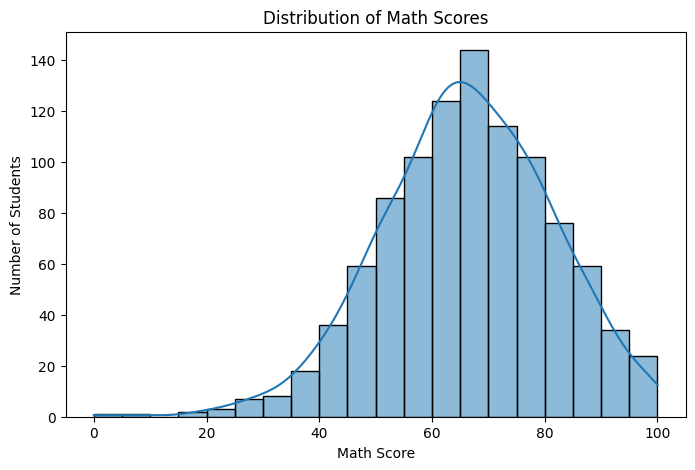

In [19]:
plt.figure(figsize=(8, 5))

sns.histplot(df['math score'], bins=20, kde=True)

plt.title('Distribution of Math Scores')
plt.xlabel('Math Score')
plt.ylabel('Number of Students')

plt.show()

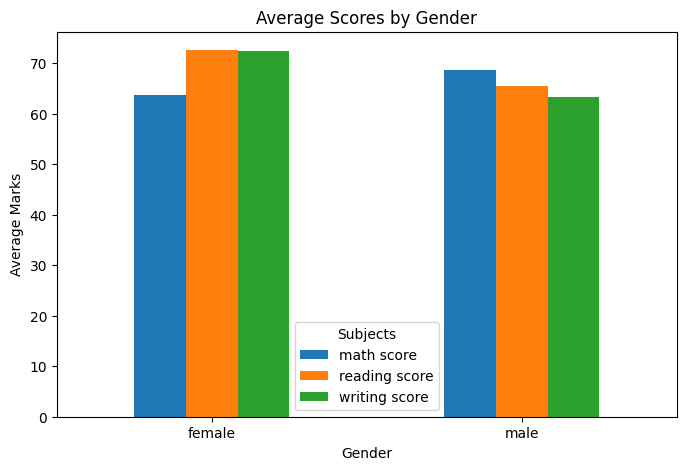

In [20]:
average_scores = df.groupby('gender')[
    ['math score', 'reading score', 'writing score']
].mean()

average_scores.plot(kind='bar', figsize=(8, 5))

plt.title('Average Scores by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Marks')
plt.xticks(rotation=0)
plt.legend(title='Subjects')
plt.show()

In [21]:
# Create a copy of the cleaned dataset
df_encoded = df.copy()

# Convert categorical columns into numerical columns
df_encoded = pd.get_dummies(
    df_encoded,
    columns=df_encoded.select_dtypes(include='object').columns,
    dtype=int
)

print("Categorical encoding completed!")
df_encoded.head()

Categorical encoding completed!


,math score,reading score,writing score,gender_female,gender_male,race/ethnicity_group A,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,race/ethnicity_group E,parental level of education_associate's degree,parental level of education_bachelor's degree,parental level of education_high school,parental level of education_master's degree,parental level of education_some college,parental level of education_some high school,lunch_free/reduced,lunch_standard,test preparation course_completed,test preparation course_none
0,72,72,74,1,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,1
1,69,90,88,1,0,0,0,1,0,0,0,0,0,0,1,0,0,1,1,0
2,90,95,93,1,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,1
3,47,57,44,0,1,1,0,0,0,0,1,0,0,0,0,0,1,0,0,1
4,76,78,75,0,1,0,0,1,0,0,0,0,0,0,1,0,0,1,0,1


In [22]:
from sklearn.preprocessing import StandardScaler

# Select numerical columns
numeric_cols = df_encoded.select_dtypes(include=np.number).columns

# Create scaler
scaler = StandardScaler()

# Apply scaling
df_encoded[numeric_cols] = scaler.fit_transform(df_encoded[numeric_cols])

print("Numerical feature scaling completed!")

df_encoded.head()

Numerical feature scaling completed!


,math score,reading score,writing score,gender_female,gender_male,race/ethnicity_group A,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,race/ethnicity_group E,parental level of education_associate's degree,parental level of education_bachelor's degree,parental level of education_high school,parental level of education_master's degree,parental level of education_some college,parental level of education_some high school,lunch_free/reduced,lunch_standard,test preparation course_completed,test preparation course_none
0,0.390024,0.193999,0.391492,0.964625,-0.964625,-0.312562,2.064742,-0.684419,-0.59583,-0.403473,-0.534179,2.733967,-0.493742,-0.250398,-0.540361,-0.466933,-0.741881,0.741881,-0.746748,0.746748
1,0.192076,1.427476,1.313269,0.964625,-0.964625,-0.312562,-0.484322,1.461094,-0.59583,-0.403473,-0.534179,-0.365769,-0.493742,-0.250398,1.850616,-0.466933,-0.741881,0.741881,1.339140,-1.339140
2,1.577711,1.770109,1.642475,0.964625,-0.964625,-0.312562,2.064742,-0.684419,-0.59583,-0.403473,-0.534179,-0.365769,-0.493742,3.993639,-0.540361,-0.466933,-0.741881,0.741881,-0.746748,0.746748
3,-1.259543,-0.833899,-1.583744,-1.036672,1.036672,3.199368,-0.484322,-0.684419,-0.59583,-0.403473,1.872032,-0.365769,-0.493742,-0.250398,-0.540361,-0.466933,1.347925,-1.347925,-0.746748,0.746748
4,0.653954,0.605158,0.457333,-1.036672,1.036672,-0.312562,-0.484322,1.461094,-0.59583,-0.403473,-0.534179,-0.365769,-0.493742,-0.250398,1.850616,-0.466933,-0.741881,0.741881,-0.746748,0.746748


In [23]:
# Save the prepared dataset
df_encoded.to_csv('/content/Prepared_StudentsPerformance.csv', index=False)

print("Prepared dataset saved successfully!")

Prepared dataset saved successfully!
